# PZ data challenge: results across all task sets

This notebook puts the results of the four task-set notebooks (`pz_challenge_taskset{1..4}_e2e.ipynb`) side by side. It covers all 16 configurations: 4 task sets × 2 sims × 2 depths. It reads the trained ensembles (the subtask 2 `.pkl` model files) those notebooks wrote to `OUT_DIR` (`outputs/znn` from scratch, `outputs/znn_pretrained_popcosmos` with pre-training, set by `PRETRAINING`; plus the method version `RUN` as a suffix) and trains nothing. All p(z)s are predicted here from those models with the current `znn` code, so the p(z) representation is the one `znn` produces now (a Gaussian with the mean and std of the predictions), whatever the run wrote as its own estimate files.

- **Part A, held-out scores** (the subtask 2 model files): each `.pkl` is reloaded and run on the same held-out split the task-set notebook used (`train_test_split` with `VAL_FRAC` and `SEED`). The results are scored with the challenge metrics, and their stacked n(z) is checked against the held-out redshift distribution. Predictions use the same photometric resampling as the submission (`N_SAMPLES` draws).
- **Part B, test-set p(z)** (optional, only with `PREDICT_TEST = True`): each model is run on its test file, as for the subtask 1 submission. The test redshifts are hidden, so this part only shows the predictions, i.e. the implied n(z) and the p(z) widths, set against the training redshift distribution.
- **Part C, challenge points** (optional, only with `SUBMISSION = True`, when preparing a submission): Part A's held-out metrics graded against the challenge tiers.

The held-out and test-set predictions are cached in `CACHE_DIR`, outside `OUT_DIR` so they stay out of the submission tarball. Delete the cache to recompute, e.g. after changing how `znn` builds the p(z). Figures (`.pdf`) and LaTeX tables (`.tex`) are saved to `PLOT_DIR`.

Run this from the repo root with the `qp` conda env as the kernel.

Plot conventions: **colour = task set** (blue TS1, green TS2, orange TS3, purple TS4), the same for all its setups. Where depths are overlaid, **line style = depth** (solid Y10, dashed Y1).

## Configuration

In [1]:
import znn  # run from the repo root so this picks up the local source

TASKSETS = [1, 2, 3, 4]
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]
TASKSET_NAMES = {
    1: "1: representative",
    2: "2: spec-selected",
    3: "3: spec + COSMOS",
    4: "4: spec + COSMOS, blended",
}

DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks
# Which run to read; must match the task-set notebooks: "popcosmos" (the pre-training shipped with znn) or None (from scratch). Each choice
# writes to its own directory, so runs with and without pre-training never overwrite each other.
PRETRAINING = "popcosmos"
# Method version, appended to OUT_DIR so runs of different versions never overwrite each other ("" for none):
# the RUN of the task-set notebooks ("noisy_kfold", plus "_frombase" with FROM_BASE); the p(z)s are predicted here
RUN = "kfold_frombase"  # set by run_challenge.py
OUT_DIR = ("outputs/znn" if PRETRAINING is None else f"outputs/znn_pretrained_{PRETRAINING}") + (f"_{RUN}" if RUN else "")  # the submission files written by the task-set notebooks
CACHE_DIR = f"{OUT_DIR}_predictions"  # held-out (part A) and test-set (part B) predictions
# Part B, at the end: predict every model's test set (as for the subtask 1 file) and show the implied n(z). It
# takes about as long as the held-out predictions, so it only runs when True
PREDICT_TEST = False
# Part C, at the end: grade the held-out metrics against the challenge tiers; only needed when preparing a submission
SUBMISSION = False
PLOT_DIR = "plots"  # figures and LaTeX tables are saved here, prefixed with the run name so runs never overwrite each other

# the held-out split: must match the task-set notebooks
VAL_FRAC = 0.2
SEED = 42
# prediction: photometric noise draws per object (converged by 50 on Cardinal Y1) and their seed
N_SAMPLES = 50
NOISE_SEED = 42

I0000 00:00:1793447238.068631 1387548 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import itertools
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

CONFIGS = list(itertools.product(TASKSETS, SIMS, SCENARIOS))
ZGRID = np.linspace(0, 3, 601)  # where p(z)s and the stacked n(z) are evaluated
# one colour per task set, the same for all its setups; its colour map is used for 2D densities
TASKSET_CMAPS = {1: "Blues", 2: "Greens", 3: "Oranges", 4: "Purples"}
COLORS = {t: plt.get_cmap(cmap)(0.7) for t, cmap in TASKSET_CMAPS.items()}
LINESTYLES = {"1yr": "--", "10yr": "-"}
TRAIN_COLOR = "0.6"
# how sims and depths are written in plots and tables
SIM_LABELS = {"cardinal": "Cardinal", "flagship": "Flagship"}
DEPTH_LABELS = {"1yr": "Y1", "10yr": "Y10"}


def label(sim, scenario):
    return f"{SIM_LABELS[sim]} {DEPTH_LABELS[scenario]}"


def style(taskset, sim, scenario):
    return dict(color=COLORS[taskset], ls=LINESTYLES[scenario], lw=1.5, label=label(sim, scenario))


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{os.path.basename(OUT_DIR)}_{name}.pdf"), bbox_inches="tight")


def save_latex(df, name, columns, caption):
    # Write df as a booktabs LaTeX table (columns: {df column: LaTeX header}) to PLOT_DIR and print it. Values of
    # 10 or more (the Anderson-Darling statistic) get one decimal, the rest four.
    df = df[list(columns)].rename(columns=columns, index=SIM_LABELS | DEPTH_LABELS)
    tex = df.rename_axis(["Task set", "Sim", "Depth"]).to_latex(
        float_format=lambda v: f"{v:.1f}" if abs(v) >= 10 else f"{v:.4f}", multirow=True, caption=caption,
        label=f"tab:{name}", position="htbp",
    )
    # a rule between task sets only, not between sims
    tex = re.sub(r"\\cline\{1-\d+\} \\cline\{2-\d+\}\n", r"\\midrule\n", tex)
    tex = re.sub(r"\\cline\{2-\d+\}\n", "", tex).replace("\\midrule\n\\bottomrule", "\\bottomrule")
    with open(os.path.join(PLOT_DIR, f"{os.path.basename(OUT_DIR)}_{name}.tex"), "w") as f:
        f.write(tex)
    print(tex)


def path(kind, taskset, sim, scenario):
    if kind in ("training", "test"):
        return os.path.join(DATA_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.hdf5")
    return os.path.join(OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.pkl")


missing = [p for c in CONFIGS if not os.path.exists(p := path("pz_model", *c))]
assert not missing, f"missing model files: {missing}"

## Reference redshifts

These are the same labels as in the task-set notebooks. Task sets 1 and 2 use `redshift`. Task sets 3 and 4 use `redshift` for spectroscopically selected objects and `redshift_manyband` for COSMOS-only objects, so scores on task sets 3 and 4 include the label noise of the COSMOS-only objects.

In [3]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object.
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        return z_spec
    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref


# Part A: held-out scores

For each configuration the model file is reloaded and run on the held-out 20% of the training file. The model was trained on the other 80%, the same split as in the task-set notebooks. Each held-out set is scored on all of its objects.

Only task set 1 has a held-out set that is representative of its test set. For the other task sets these scores are **optimistic** for the test set.


In [4]:
def heldout_predictions(taskset, sim, scenario):
    # Held-out reference z, i-mag, zmode, the p(z) mean and std, and the ensemble's p(z) (a qp
    # ensemble) under "pz". Cached in CACHE_DIR: the arrays in <stem>.npz, the p(z) in <stem>.hdf5.
    stem = os.path.join(CACHE_DIR, f"taskset_{taskset}_{sim}_{scenario}_pz")
    if os.path.exists(f"{stem}.npz") and os.path.exists(f"{stem}.hdf5"):
        return dict(np.load(f"{stem}.npz")) | {"pz": qp.read(f"{stem}.hdf5")}

    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]

    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED)
    )
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "zmode": np.squeeze(pz.ancil["zmode"]),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
    }
    np.savez(f"{stem}.npz", **out)
    pz.write_to(f"{stem}.hdf5")
    return out | {"pz": pz}


heldout = {}
for c in CONFIGS:
    print("held-out predictions:", *c)
    heldout[c] = heldout_predictions(*c)

held-out predictions: 1 cardinal 1yr
held-out predictions: 1 cardinal 10yr
held-out predictions: 1 flagship 1yr
held-out predictions: 1 flagship 10yr
held-out predictions: 2 cardinal 1yr
held-out predictions: 2 cardinal 10yr
held-out predictions: 2 flagship 1yr
held-out predictions: 2 flagship 10yr
held-out predictions: 3 cardinal 1yr
held-out predictions: 3 cardinal 10yr
held-out predictions: 3 flagship 1yr
held-out predictions: 3 flagship 10yr
held-out predictions: 4 cardinal 1yr
held-out predictions: 4 cardinal 10yr
held-out predictions: 4 flagship 1yr
held-out predictions: 4 flagship 10yr


In [5]:
def challenge_metrics(z_ref, zmode, pz):
    # The challenge's seven scored metrics, computed as in the task-set notebooks.
    dz = (zmode - z_ref) / (1 + z_ref)
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pit = PIT(pz, z_ref)
    return {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        # qp derives this from a spline fit to the PIT quantiles and it breaks down (negative or huge values)
        # when PIT piles up at 0 or 1; the challenge evaluator uses the same call, so it is what gets scored
        "outlier": pit.evaluate_PIT_outlier_rate(),
    }, pit.pit_samps


results, pits = {}, {}
for c, h in heldout.items():
    results[c], pits[c] = challenge_metrics(h["z_ref"], h["zmode"], h["pz"])

# ks and CvM are only used for the challenge points (Part C)
table = pd.DataFrame(results).T[["mean", "std", "abs_outlier_rate", "ksamp", "outlier"]]
table.index.names = ["taskset", "sim", "scenario"]
table.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean     std  abs_outlier_rate      ksamp  \
taskset sim      scenario                                                
1       cardinal 1yr       0.0010  0.0177            0.0014   120.3680   
                 10yr      0.0015  0.0112            0.0002   170.3973   
        flagship 1yr       0.0011  0.0200            0.0011   268.1011   
                 10yr     -0.0004  0.0125            0.0000   295.7592   
2       cardinal 1yr       0.0041  0.0233            0.0082   393.2011   
                 10yr      0.0009  0.0146            0.0006   153.1649   
        flagship 1yr       0.0004  0.0267            0.0072   200.2872   
                 10yr     -0.0001  0.0151            0.0001   292.8473   
3       cardinal 1yr       0.0059  0.0293            0.0506   672.1303   
                 10yr      0.0037  0.0192            0.0266   497.9149   
        flagship 1yr       0.0027  0.0393            0.0844   574.9343   
                 10yr      0.0011  0.0271            0.0430   504.8423   
4       cardinal 1yr       0.0044  0.0306            0.0546   540.5791   
                 10yr      0.0029  0.0200            0.0284   472.3808   
        flagship 1yr      -0.0004  0.0401            0.0842   463.1396   
                 10yr      0.0035  0.0291            0.0507  1054.4930   

                           outlier  
taskset sim      scenario           
1       cardinal 1yr        0.0081  
                 10yr       0.0010  
        flagship 1yr        0.0059  
                 10yr       0.0082  
2       cardinal 1yr        0.0095  
                 10yr       0.0016  
        flagship 1yr        0.0105  
                 10yr       0.0129  
3       cardinal 1yr        0.0226  
                 10yr       1.1442  
        flagship 1yr        0.1145  
                 10yr       0.1062  
4       cardinal 1yr        0.0320  
                 10yr       0.0305  
        flagship 1yr       -0.0356  
                 10yr       0.9085

### p(z) metrics

What each column of the table above measures, all on the held-out set. Lower is better for all of them except `mean`, which should be close to 0.

Point-estimate metrics, on Δz = (zmode − z_ref)/(1 + z_ref). They are computed after 3σ-clipping Δz four times, as in `znn.get_biweight_mean_sigma_outlier`:
- `mean`: the bias, the biweight location of the clipped Δz.
- `std`: the scatter, the biweight scale of the clipped Δz (a robust standard deviation).
- `abs_outlier_rate`: the fraction of *all* objects (not clipped) with |Δz| > 0.2.

Calibration metrics, on the PIT (the CDF of each p(z) evaluated at its z_ref). These should be uniform on [0, 1] if the p(z)s are calibrated:
- `ksamp`: Anderson–Darling k-sample statistic between the PIT values and a uniform sample. It weights the tails (PIT near 0 and 1) more than a KS test does, so it reacts most to catastrophic misses. It grows with the number of objects.
- `outlier`: the fraction of PIT values below 0.0001 or above 0.9999, i.e. z_ref far out in the tails of its p(z). qp estimates it from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1. The challenge evaluator uses the same call, so this is the value that gets scored.

The challenge also scores the KS and Cramér–von Mises statistics of the PIT. They are computed for Part C but left out of the table; the PIT histograms below show the calibration directly.


In [6]:
save_latex(
    table,
    "pz_metrics",
    {
        "mean": r"bias",
        "std": r"$\sigma$",
        "abs_outlier_rate": r"$f_{|\Delta z| > 0.2}$",
        "ksamp": r"AD",
        "outlier": r"$f_\mathrm{PIT\,out}$",
    },
    r"p(z) metrics on the held-out set. Point estimates: bias, scatter $\sigma$ and outlier fraction of "
    r"$\Delta z = (z_\mathrm{mode} - z_\mathrm{ref})/(1 + z_\mathrm{ref})$. Calibration: Anderson--Darling "
    r"statistic of the PIT against uniform and the fraction of PIT outliers.",
)


\begin{table}[htbp]
\caption{p(z) metrics on the held-out set. Point estimates: bias, scatter $\sigma$ and outlier fraction of $\Delta z = (z_\mathrm{mode} - z_\mathrm{ref})/(1 + z_\mathrm{ref})$. Calibration: Anderson--Darling statistic of the PIT against uniform and the fraction of PIT outliers.}
\label{tab:pz_metrics}
\begin{tabular}{lllrrrrr}
\toprule
 &  &  & bias & $\sigma$ & $f_{|\Delta z| > 0.2}$ & AD & $f_\mathrm{PIT\,out}$ \\
Task set & Sim & Depth &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{1} & \multirow[t]{2}{*}{Cardinal} & Y1 & 0.0010 & 0.0177 & 0.0014 & 120.4 & 0.0081 \\
 &  & Y10 & 0.0015 & 0.0112 & 0.0002 & 170.4 & 0.0010 \\
 & \multirow[t]{2}{*}{Flagship} & Y1 & 0.0011 & 0.0200 & 0.0011 & 268.1 & 0.0059 \\
 &  & Y10 & -0.0004 & 0.0125 & 0.0000 & 295.8 & 0.0082 \\
\midrule
\multirow[t]{4}{*}{2} & \multirow[t]{2}{*}{Cardinal} & Y1 & 0.0041 & 0.0233 & 0.0083 & 393.2 & 0.0095 \\
 &  & Y10 & 0.0009 & 0.0146 & 0.0006 & 153.2 & 0.0016 \\
 & \multirow[t]{2}{*}{Flagship} & Y

### PIT

PIT histograms on the held-out set. A flat histogram means the p(z) is calibrated. A U shape means it is too narrow, and a hump means it is too wide.

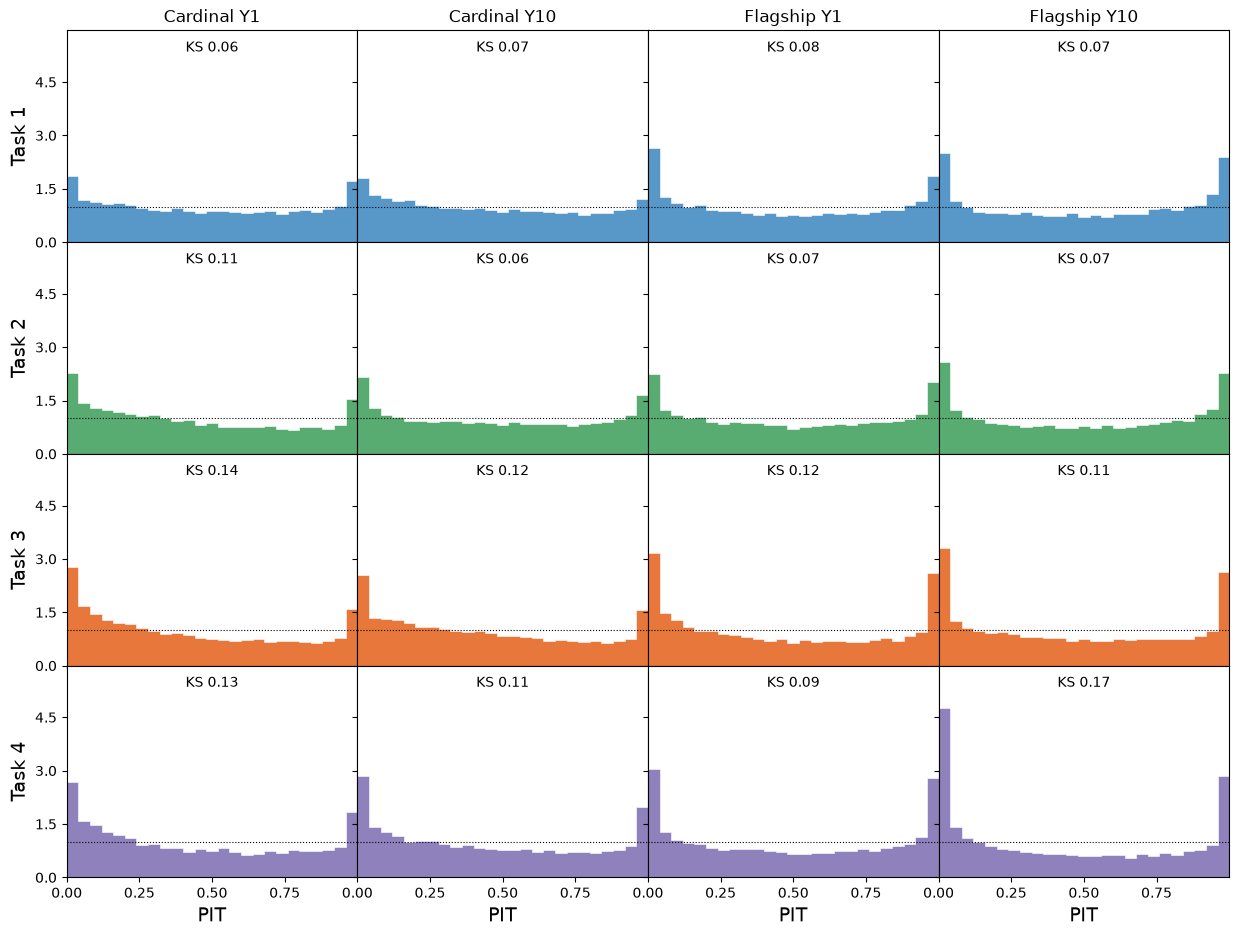

In [16]:
from matplotlib.ticker import MaxNLocator

pit_bins = np.linspace(0, 1, 26)
top = 0
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        heights, _, _ = ax.hist(pits[(taskset, sim, scenario)], pit_bins, density=True, color=COLORS[taskset],
                histtype="stepfilled", alpha=0.8, ec="white", lw=0.5)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ks = results[(taskset, sim, scenario)]["ks"]
        ax.text(0.5, 0.95, f"KS {ks:.2f}", transform=ax.transAxes, ha="center", va="top", fontsize=10,
                bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
        top = max(top, heights.max())
        if row == 0:
            ax.set_title(label(sim, scenario), fontsize=12)
        if col == 0:
            ax.set_ylabel(f"Task {taskset}")
        if row == 3:
            ax.set_xlabel("PIT")
# with no gaps, keep the ticks off the panel edges so labels of neighbouring panels do not touch
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_ylim(0, 1.25 * top)  # headroom for the KS labels
axes[0, 0].set_xticks([0, 0.25, 0.5, 0.75])
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=4, prune="upper"))
save(fig, "pit")
plt.show()

### Point estimates

`zmode` against the reference redshift on the held-out set (log-density 2D histogram). The dashed lines mark |Δz|/(1+z) = 0.2, the outlier threshold.

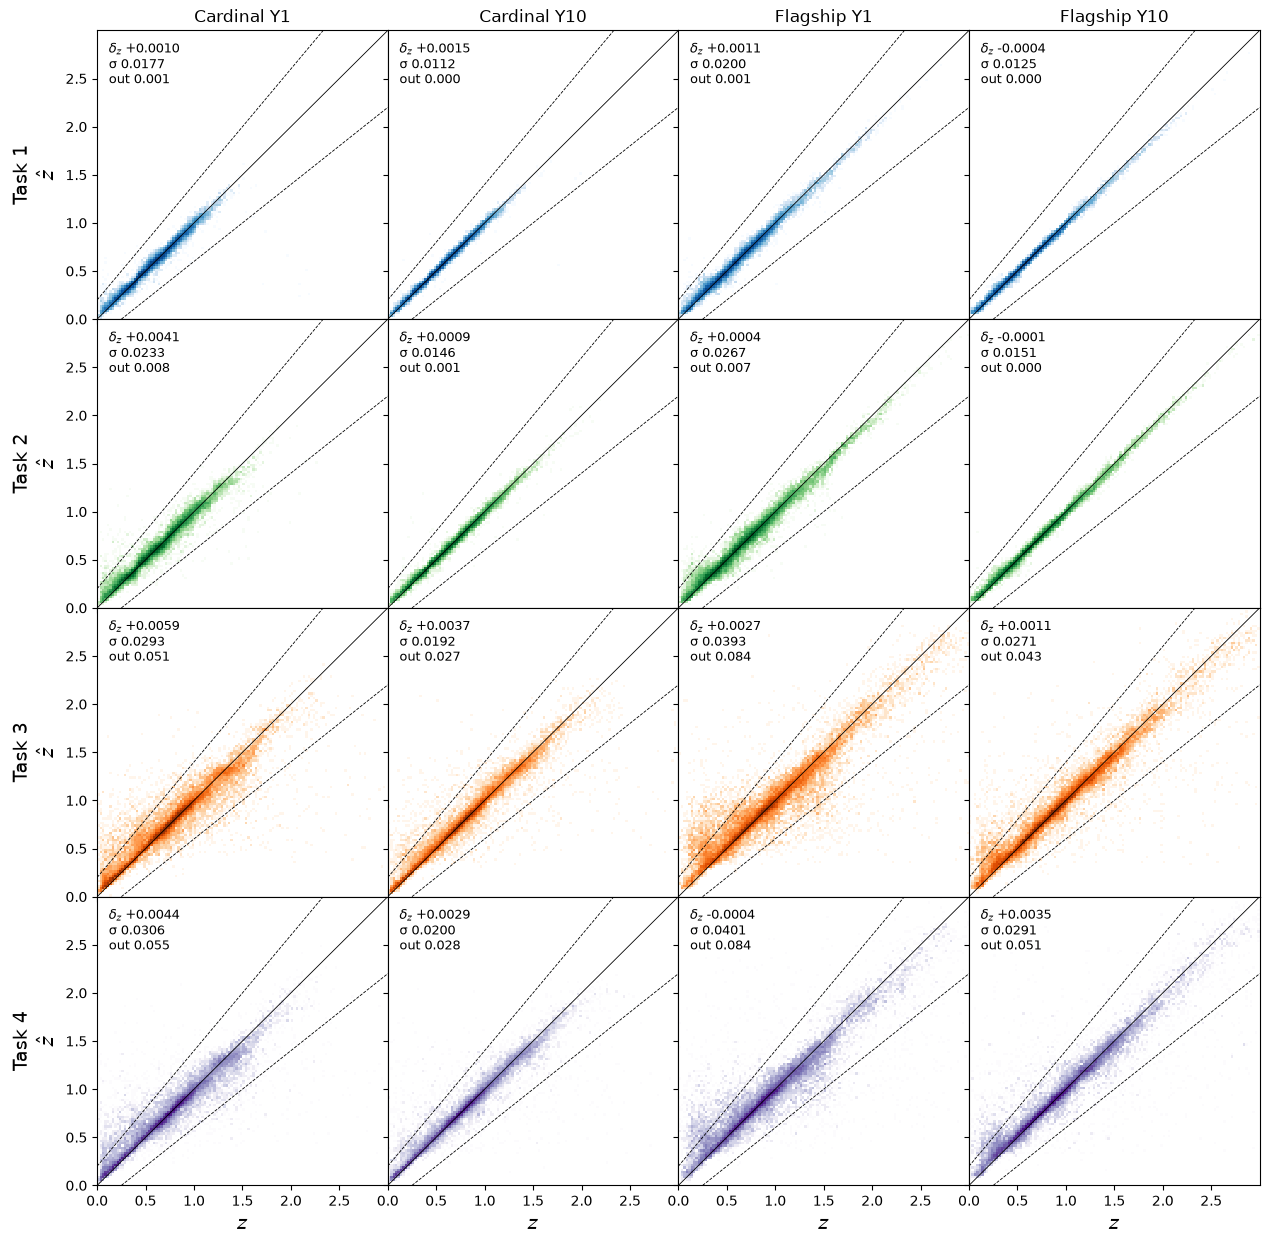

In [17]:
from matplotlib.colors import LogNorm

zb = np.linspace(0, 3, 121)
fig, axes = plt.subplots(4, 4, figsize=(15, 15), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        h = heldout[(taskset, sim, scenario)]
        ax.hist2d(h["z_ref"], h["zmode"], bins=[zb, zb], cmap=TASKSET_CMAPS[taskset], norm=LogNorm(), rasterized=True)
        ax.plot(zb, zb, color="k", lw=0.6)
        for sgn in (-1, 1):
            ax.plot(zb, zb + sgn * 0.2 * (1 + zb), color="k", lw=0.6, ls="--")
        v = table.loc[(taskset, sim, scenario)]
        ax.text(0.04, 0.96, f"$\\delta_z$ {v['mean']:+.4f}\nσ {v['std']:.4f}\nout {v['abs_outlier_rate']:.3f}",
                transform=ax.transAxes, va="top", fontsize=9)
        if row == 0:
            ax.set_title(label(sim, scenario), fontsize=12)
        if col == 0:
            ax.set_ylabel(f"Task {taskset}\n$\\hat{{z}}$")
        if row == 3:
            ax.set_xlabel("$z$")
axes[0, 0].set_xlim(0, 3)
axes[0, 0].set_ylim(0, 3)
# ticks stop short of 3 so labels of neighbouring panels do not touch
axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
axes[0, 0].set_yticks(np.arange(0, 3, 0.5))
save(fig, "zphot_vs_zref")
plt.show()

### n(z)

The predicted n(z) of each held-out set against its reference redshifts. One redshift is drawn from every object's p(z) and the draws are histogrammed. Repeating this `N_NZ_DRAWS` times gives the predicted n(z) in each bin (points: the mean over the draws, i.e. the stacked p(z)) and its uncertainty (error bars: the standard deviation over the draws). If the p(z)s are calibrated, the histogram of the reference redshifts (black) is one more such draw and should agree with the points within the error bars. The test redshifts are hidden, so this uses the held-out set, which is only representative of the test set for task set 1.

The table compares the two distributions, predicted minus reference: `Δ<z>` is the change in mean redshift and `Δσ_z` the change in width (standard deviation), both averaged over the draws. `KS` is the two-sample Kolmogorov-Smirnov statistic between the reference redshifts and all the draws pooled, i.e. the stacked p(z).


In [19]:
from matplotlib.ticker import MaxNLocator
from scipy.stats import ks_2samp

NZ_BINS = np.linspace(0, 3, 61)
NZ_CENTRES = 0.5 * (NZ_BINS[1:] + NZ_BINS[:-1])
N_NZ_DRAWS = 1_000
nz_rng = np.random.default_rng(NOISE_SEED)


def nz_hist(z):
    # n(z) normalised over all objects, so draws outside NZ_BINS (e.g. z < 0) lower it rather than being dropped
    return np.histogram(z, NZ_BINS)[0] / (len(z) * np.diff(NZ_BINS))


nz_pred, nz_true, nz_metrics = {}, {}, {}
for c, h in heldout.items():
    z_draws = h["pz"].rvs(size=N_NZ_DRAWS, random_state=nz_rng)  # (objects, draws)
    nz_pred[c] = np.stack([nz_hist(zd) for zd in z_draws.T])
    nz_true[c] = nz_hist(h["z_ref"])
    nz_metrics[c] = {
        "Δ<z>": z_draws.mean(axis=0).mean() - h["z_ref"].mean(),
        "Δσ_z": z_draws.std(axis=0).mean() - h["z_ref"].std(),
        "KS": ks_2samp(h["z_ref"], z_draws.ravel()).statistic,
    }

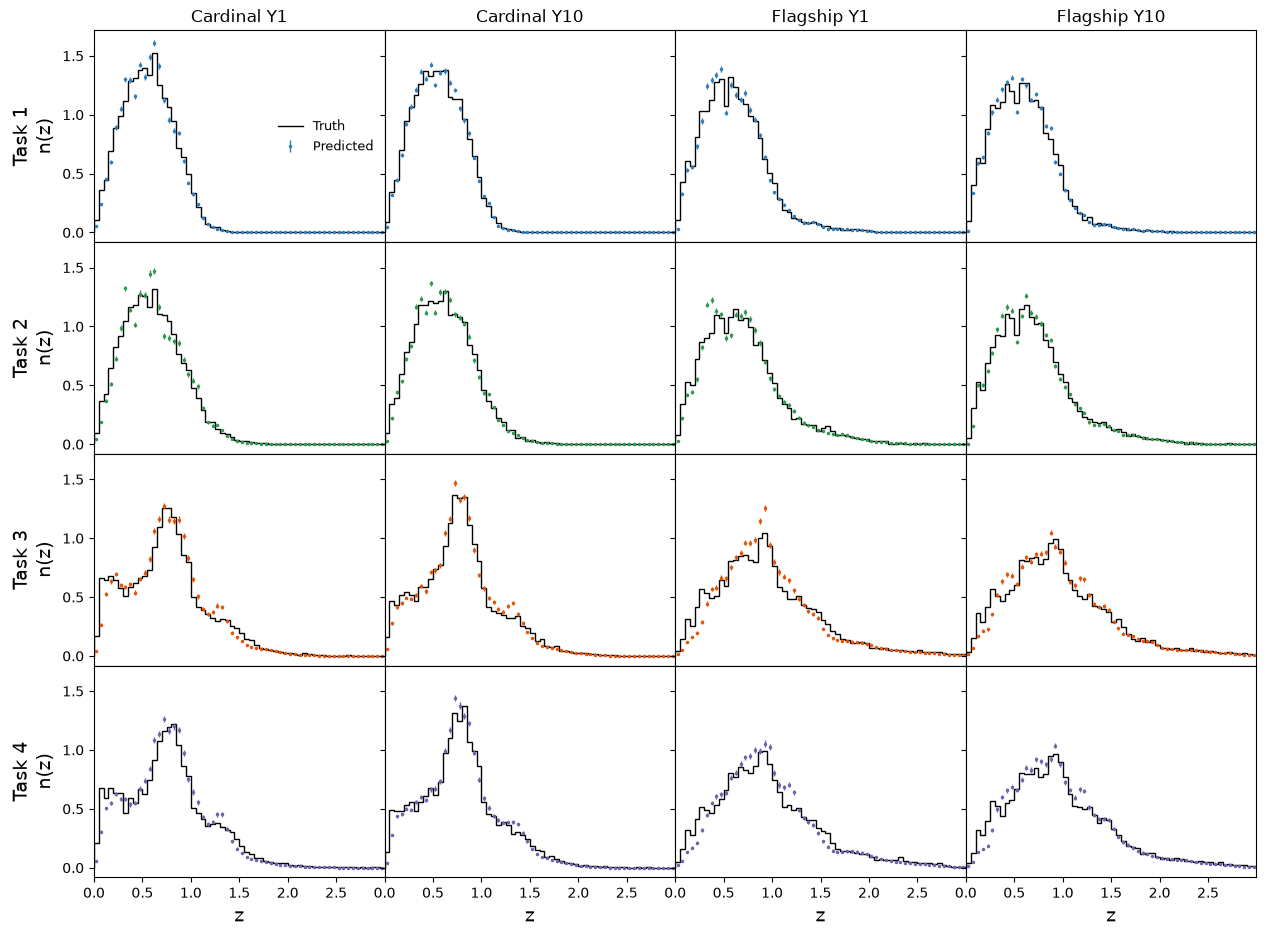

\begin{table}[htbp]
\caption{Predicted against held-out n(z): change in mean redshift $\Delta\langle z \rangle$ and in width $\Delta\sigma_z$ (predicted minus reference), and the two-sample Kolmogorov--Smirnov statistic between the reference redshifts and redshifts drawn from the p(z)s.}
\label{tab:nz_metrics}
\begin{tabular}{lllrrr}
\toprule
 &  &  & $\Delta\langle z \rangle$ & $\Delta\sigma_z$ & KS \\
Task set & Sim & Depth &  &  &  \\
\midrule
\multirow[t]{4}{*}{1} & \multirow[t]{2}{*}{Cardinal} & Y1 & 0.0005 & -0.0079 & 0.0138 \\
 &  & Y10 & 0.0018 & -0.0037 & 0.0116 \\
 & \multirow[t]{2}{*}{Flagship} & Y1 & 0.0016 & -0.0085 & 0.0225 \\
 &  & Y10 & -0.0010 & -0.0096 & 0.0138 \\
\midrule
\multirow[t]{4}{*}{2} & \multirow[t]{2}{*}{Cardinal} & Y1 & 0.0074 & -0.0101 & 0.0271 \\
 &  & Y10 & 0.0007 & -0.0080 & 0.0160 \\
 & \multirow[t]{2}{*}{Flagship} & Y1 & 0.0001 & -0.0139 & 0.0288 \\
 &  & Y10 & -0.0003 & -0.0102 & 0.0176 \\
\midrule
\multirow[t]{4}{*}{3} & \multirow[t]{2}{*}{Cardinal

Δ<z>    Δσ_z      KS
taskset sim      scenario                        
1       cardinal 1yr       0.0005 -0.0079  0.0138
                 10yr      0.0018 -0.0037  0.0116
        flagship 1yr       0.0016 -0.0085  0.0225
                 10yr     -0.0010 -0.0096  0.0138
2       cardinal 1yr       0.0074 -0.0101  0.0271
                 10yr      0.0007 -0.0080  0.0160
        flagship 1yr       0.0001 -0.0139  0.0288
                 10yr     -0.0003 -0.0102  0.0176
3       cardinal 1yr       0.0045 -0.0549  0.0346
                 10yr      0.0055 -0.0361  0.0222
        flagship 1yr       0.0018 -0.0721  0.0494
                 10yr      0.0017 -0.0515  0.0404
4       cardinal 1yr       0.0056 -0.0534  0.0380
                 10yr      0.0000 -0.0446  0.0234
        flagship 1yr      -0.0025 -0.0673  0.0420
                 10yr      0.0050 -0.0579  0.0453

In [18]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        c = (taskset, sim, scenario)
        ax.stairs(nz_true[c], NZ_BINS, color="k", lw=1.0, label="Truth")
        ax.errorbar(NZ_CENTRES, nz_pred[c].mean(axis=0), nz_pred[c].std(axis=0), fmt=".", ms=3, lw=1, capsize=0,
                    color=COLORS[taskset], label="Predicted")
        m = nz_metrics[c]
        #ax.text(0.97, 0.92, f"Δ<z> {m['Δ<z>']:+.4f}\nΔσ_z {m['Δσ_z']:+.4f}\nKS {m['KS']:.3f}",
        #        transform=ax.transAxes, ha="right", va="top", fontsize=9)
        if row == 0:
            ax.set_title(label(sim, scenario), fontsize=12)
        if col == 0:
            ax.set_ylabel(f"Task {taskset}\nn(z)")
        if row == 3:
            ax.set_xlabel("z")
axes[0, 0].legend(fontsize=9, frameon=False, loc="center right")
# with no gaps, keep the ticks off the panel edges so labels of neighbouring panels do not touch
axes[0, 0].set_xlim(0, 3)
axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=4, prune="upper"))
save(fig, "nz_heldout")
plt.show()

nz_table = pd.DataFrame.from_dict(nz_metrics, orient="index")
nz_table.index.names = table.index.names
save_latex(
    nz_table,
    "nz_metrics",
    {"Δ<z>": r"$\Delta\langle z \rangle$", "Δσ_z": r"$\Delta\sigma_z$", "KS": r"KS"},
    r"Predicted against held-out n(z): change in mean redshift $\Delta\langle z \rangle$ and in width $\Delta\sigma_z$ "
    r"(predicted minus reference), and the two-sample Kolmogorov--Smirnov statistic between the reference redshifts and "
    r"redshifts drawn from the p(z)s.",
)
nz_table.round(4)


# Part B: test-set p(z)

Runs only with `PREDICT_TEST = True`.


Each model is run on its test file (`N_SAMPLES` noise draws, as for the submission), giving per-object Gaussian p(z)s with the mean and std of all `N_SAMPLES` × members predictions. They are cached in `CACHE_DIR`, and summarised by their `zmode` (the challenge's point estimate), mean and std, and matched to its test catalogue by `object_id` to pick up the i-band magnitude.

In [10]:
def test_predictions(taskset, sim, scenario):
    # The model's test-set p(z) (a qp ensemble), predicted as for the subtask 1 file. Cached in CACHE_DIR.
    cache = os.path.join(CACHE_DIR, f"test_taskset_{taskset}_{sim}_{scenario}_pz.hdf5")
    if os.path.exists(cache):
        return qp.read(cache)
    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    test = znn.read_catalog(path("test", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.predict_from_catalog(
        trained_models, test, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED),
        ids=test["object_id"].to_numpy(),
    )
    pz.write_to(cache)
    return pz


def read_estimate(taskset, sim, scenario):
    # Per-object summaries of the test-set p(z), and the stacked n(z) (mean p(z)) on ZGRID.
    pz = test_predictions(taskset, sim, scenario)
    est = pd.DataFrame(
        {
            "object_id": np.squeeze(pz.ancil["object_id"]),
            "zmode": np.squeeze(pz.ancil["zmode"]),
            "mean": np.squeeze(pz.mean()),
            "std": np.squeeze(pz.std()),
        }
    )
    test = znn.read_catalog(path("test", taskset, sim, scenario), columns=["object_id", "mag_i_lsst"])
    est = est.merge(test, on="object_id", how="left", validate="one_to_one")
    assert est["mag_i_lsst"].notna().all()
    return est, pz.pdf(ZGRID).mean(axis=0)


if PREDICT_TEST:
    estimates, stacked_nz, train_z = {}, {}, {}
    for c in CONFIGS:
        print("test-set predictions:", *c)
        estimates[c], stacked_nz[c] = read_estimate(*c)
        train = znn.read_catalog(path("training", *c))
        train_z[c] = reference_redshifts(train)

    summary = pd.DataFrame(
        {
            c: {
                "N test": len(e),
                "median zmode": e["zmode"].median(),
                "median σ": e["std"].median(),
                "median σ/(1+z)": (e["std"] / (1 + e["zmode"])).median(),
                "frac z < 0": (e["zmode"] < 0).mean(),
                "median i (test)": e["mag_i_lsst"].median(),
            }
            for c, e in estimates.items()
        }
    ).T
    summary.index.names = ["taskset", "sim", "scenario"]
    display(summary.round(4))


### Implied n(z) of the test set

The stacked test-set p(z) (the mean of the per-object p(z)s) against the training reference redshifts (grey, 10yr file). Task set 1 should agree with training. For task sets 2–4 the test set is fainter than the training set, so any difference between the two shows how far the model has to extrapolate.

In [11]:
if PREDICT_TEST:
    fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True, sharey=True)
    for col, taskset in enumerate(TASKSETS):
        for row, sim in enumerate(SIMS):
            ax = axes[row, col]
            ax.hist(train_z[(taskset, sim, "10yr")], bins=np.linspace(0, 3, 61), density=True,
                    histtype="stepfilled", color=TRAIN_COLOR, alpha=0.35, label="training z_ref")
            for scenario in SCENARIOS:
                ax.plot(ZGRID, stacked_nz[(taskset, sim, scenario)], **style(taskset, sim, scenario))
            ax.axvline(0, color="k", lw=0.5)
            if row == 0:
                ax.set_title(f"task set {TASKSET_NAMES[taskset]}", fontsize=12)
            if row == 1:
                ax.set_xlabel("z")
            if col == 0:
                ax.set_ylabel(f"{SIM_LABELS[sim]}\nn(z)")
            ax.legend(fontsize=9, frameon=False)
    fig.tight_layout()
    save(fig, "nz")
    plt.show()

# Part C: challenge points

Runs only with `SUBMISSION = True`, when preparing a submission.

Part A's held-out metrics graded against the challenge tiers (`pz_data_challenge.scoring.metric_dict`). There is one point per nested range a metric falls inside, so at most 3 per metric and 21 per configuration.

A 0 under `outlier` is usually not a real failure. qp computes that metric from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1, so check the PIT histograms in Part A. The challenge evaluator makes the same call, so these are the points it would award.


In [12]:
def tier_points(values):
    return {name: sum(lo <= float(values[name]) <= hi for lo, hi in ranges) for name, ranges in scoring.metric_dict.items()}


if SUBMISSION:
    points = pd.DataFrame({k: tier_points(v) for k, v in results.items()}).T
    points.index.names = table.index.names
    points["total"] = points.sum(axis=1)
    N_MAX = sum(len(r) for r in scoring.metric_dict.values())

    labels = [f"TS{t} {label(s, y)}" for t, s, y in points.index]
    metrics = list(scoring.metric_dict)

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(points[metrics].to_numpy(), cmap="Blues", vmin=-0.5, vmax=3.5, aspect="auto")
    for (i, j), v in np.ndenumerate(points[metrics].to_numpy()):
        ax.text(j, i, int(v), ha="center", va="center", fontsize=10, color="white" if v >= 2 else "black")
    ax.set_xticks(range(len(metrics)), metrics, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), [f"{l}   ({t}/{N_MAX})" for l, t in zip(labels, points["total"])])
    for y in (3.5, 7.5, 11.5):
        ax.axhline(y, color="white", lw=3)
    ax.set_title("points per metric (held-out)")
    fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3], shrink=0.6, label="points")
    fig.tight_layout()
    save(fig, "points")
    plt.show()

    print("total points per task set (sum over its 4 configurations, held-out):")
    print(points["total"].groupby(level="taskset").sum().to_string(), f"\n(out of {4 * N_MAX} each)")


# Appendix: what the CNN sees

The model does not take the band magnitudes as a list. Each magnitude (minus the reference i band) is spread over wavelength with its filter curve, and the result is averaged into `n_bins` equal-width wavelength bins. This gives a continuous curve (channel 0 of `X`), which is shown here for a few held-out galaxies across redshift.

- **Left:** the encoding of the catalogue photometry, drawn through the `n_bins` bin centres as in `znn.visualize_the_data`. The shaded band is the 16–84% range over `N_DRAWS` photometric resamplings, i.e. the noise the ensemble sees in training and at prediction time. The filter curves are in the strip on top. Bins with no observed band are 0 (and have 0 in the coverage channel).
- **Right:** the predicted p(z) for that galaxy from Part A (built from all its predictions), with the reference redshift as a dashed line.

I0000 00:00:1793447299.950823 1387548 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 30433 MB memory:  -> device: 0, name: NVIDIA A100-PCIE-40GB, pci bus id: 0000:c3:00.0, compute capability: 8.0


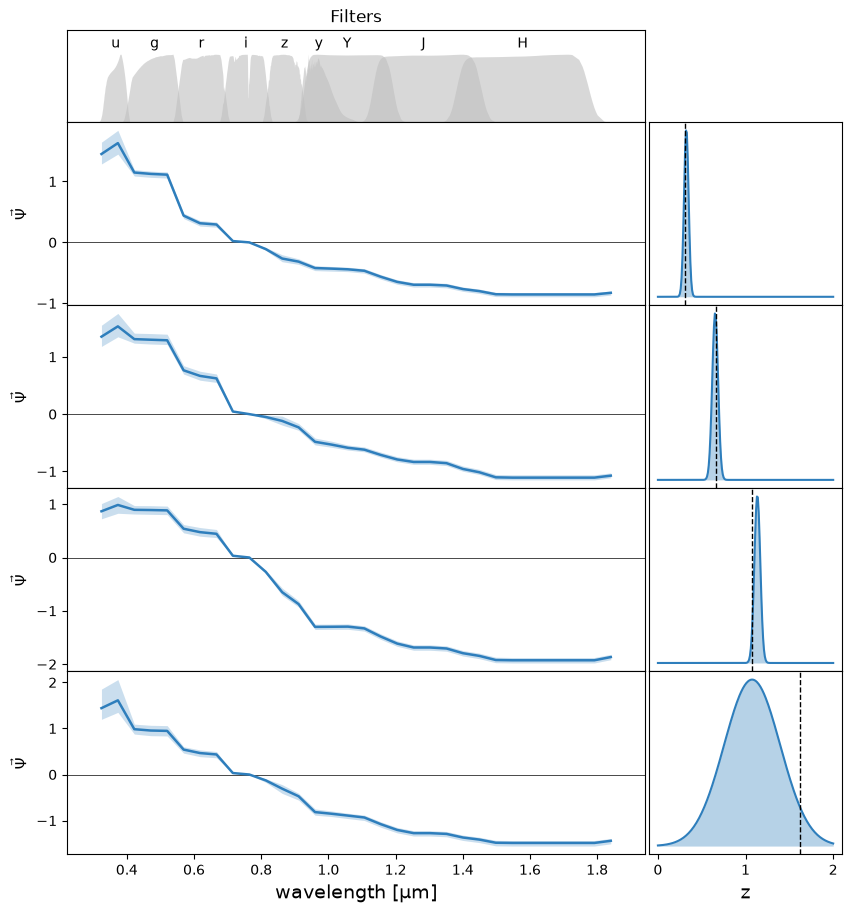

In [13]:
EXAMPLE = (1, "cardinal", "1yr")  # (task set, sim, depth); 1yr makes the photometric errors easier to see
Z_TARGETS = [0.3, 0.7, 1.1, 1.6]# 2.2]  # one galaxy picked near each reference redshift
IMAG_RANGE = (22.0, 23.5)  # faint enough for the errors to show
N_DRAWS = 200
ZGRID = np.linspace(0, 2, 201) 
rng = np.random.default_rng(1)

train = znn.read_catalog(path("training", *EXAMPLE))
_, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
h = heldout[EXAMPLE]
_, features = znn.load_ensemble_file(path("pz_model", *EXAMPLE))
bands, curves, cfg = features["bands"], features["filter_curves"], features["config"]
errors = {col: f"{col}_err" for col, _ in bands.values()}

in_mag = (h["mag_i"] > IMAG_RANGE[0]) & (h["mag_i"] < IMAG_RANGE[1])
picks = [rng.choice(np.flatnonzero(in_mag & (np.abs(h["z_ref"] - zt) < 0.05))) for zt in Z_TARGETS]
gal = train.iloc[idx_val[picks]]

# wavelength bin centres, as catalog_to_XY builds them
lambda_common = np.linspace(min(c[:, 0].min() for c in curves.values()), max(c[:, 0].max() for c in curves.values()), cfg["n_lambda"])
lam_bins, _ = znn.make_lambda_bins(lambda_common, cfg["n_bins"])
lam_eff = {b: np.sum(c[:, 0] * c[:, 1]) / np.sum(c[:, 1]) for b, c in curves.items()}

X_obs, _ = znn.catalog_to_XY(gal, **features)
enc_draws = [znn.catalog_to_XY(znn.resample_photometry(gal, errors, rng), **features)[0][..., 0] for _ in range(N_DRAWS)]
enc_lo, enc_hi = np.percentile(enc_draws, [16, 84], axis=0)

ENC = COLORS[EXAMPLE[0]]
um = 1e-4  # filter curves are in Angstrom
fig, axes = plt.subplots(
    len(picks) + 1, 2, figsize=(10, 2.3 * len(picks) + 1.5), sharex="col",
    gridspec_kw=dict(height_ratios=[0.5] + [1] * len(picks), width_ratios=[3, 1], hspace=0.0, wspace=0.01),
)
for b, c in curves.items():
    axes[0, 0].fill_between(c[:, 0] * um, c[:, 1] / c[:, 1].max(), color="0.75", alpha=0.6, lw=0)
    axes[0, 0].text(lam_eff[b] * um, 1.05, b, ha="center", va="bottom", fontsize=10)
axes[0, 0].set_ylim(0, 1.35)
axes[0, 0].set_yticks([])
#axes[0, 0].set_ylabel("filters", fontsize=11)
axes[0, 1].axis("off")

for row, (k, j) in enumerate(zip(range(len(picks)), picks), start=1):
    ax = axes[row, 0]
    ax.axhline(0, color="k", lw=0.5)
    ax.fill_between(lam_bins * um, enc_lo[k], enc_hi[k], color=ENC, alpha=0.25, lw=0)
    ax.plot(lam_bins * um, X_obs[k, :, 0], color=ENC, lw=1.8)
    ax.set_ylabel(r"$\vec{\Psi}$", fontsize=11)
    #ax.text(0.99, 0.92, f"i = {h['mag_i'][j]:.2f}   z_ref = {h['z_ref'][j]:.2f}   zmode = {h['zmode'][j]:.2f}",
    #        transform=ax.transAxes, ha="right", va="top", fontsize=10)

    ax = axes[row, 1]
    pdf = np.squeeze(h["pz"][[j]].pdf(ZGRID))
    ax.fill_between(ZGRID, pdf, color=ENC, alpha=0.35, lw=0)
    ax.plot(ZGRID, pdf, color=ENC, lw=1.5)
    ax.axvline(h["z_ref"][j], color="k", ls="--", lw=1)
    ax.set_yticks([])
axes[-1, 0].set_xlabel("wavelength [μm]")
axes[-1, 1].set_xlabel("z")
axes[0, 0].set_title("Filters", fontsize=12)
save(fig, "encoding")
plt.show()